# PCA

    Imports

In [5]:
import numpy as np
import scanpy as sc
from sklearn.decomposition import PCA

Data loading

In [ ]:
adata = sc.read_h5ad("../Data/preprocessed.h5ad")

adata

adata.obsm["X_pca"].shape

# X = adata.layers["log_normalized"]
X = adata[:, adata.var["highly_variable"]].layers["log_normalized"]

if not isinstance(X, np.ndarray):
    X = X.toarray()

PCA

In [22]:
pca = PCA(n_components=50)
pca.fit(X)

X_pca = pca.transform(X)

# Variance expliquée par chaque composante
print(pca.explained_variance_ratio_)

# Variance expliquée cumulée
print(np.cumsum(pca.explained_variance_ratio_))

# Contributions des variables (loadings)
print(pca.components_)

[0.15136814 0.05230635 0.0502187  0.0359913  0.02743892 0.01341754
 0.01217538 0.01008009 0.00986258 0.00852971 0.00793718 0.00719901
 0.00608791 0.00563135 0.00550501 0.00475314 0.00458464 0.00415757
 0.00381693 0.00341326 0.00338817 0.00325189 0.00301612 0.00299635
 0.00268556 0.00263469 0.00254242 0.00246741 0.00242497 0.00228589
 0.00224825 0.00211415 0.0020765  0.00202622 0.00197039 0.0019373
 0.00187744 0.00182122 0.00178785 0.00174755 0.00173137 0.00171818
 0.00167108 0.00163603 0.00160833 0.00157322 0.00153324 0.00149815
 0.00148975 0.00144102]
[0.15136814 0.2036745  0.2538932  0.2898845  0.31732342 0.33074096
 0.34291634 0.35299644 0.362859   0.37138873 0.3793259  0.38652492
 0.39261281 0.39824417 0.40374917 0.4085023  0.41308695 0.41724452
 0.42106146 0.42447472 0.42786288 0.43111476 0.43413088 0.43712723
 0.4398128  0.44244748 0.4449899  0.4474573  0.4498823  0.4521682
 0.45441645 0.4565306  0.4586071  0.46063334 0.46260372 0.46454102
 0.46641845 0.46823967 0.4700275  0.4717

PCA Visualsation

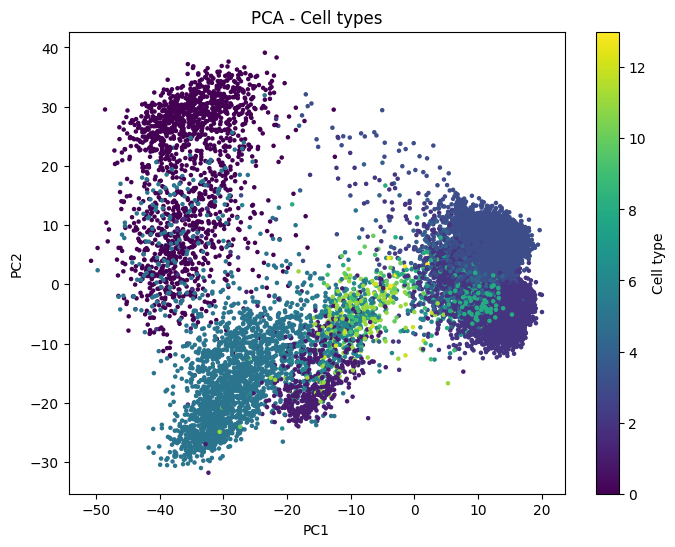

In [24]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=adata.obs["celltype"].astype("category").cat.codes,
    cmap="viridis",
    s=5
)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA - Cell types")
plt.colorbar(label="Cell type")
plt.show()

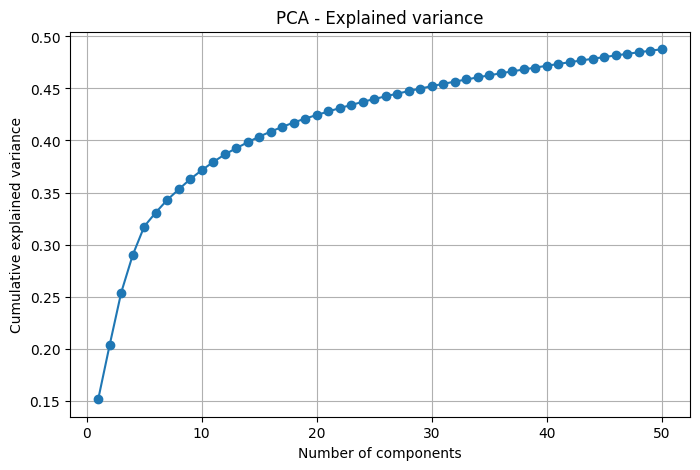

In [26]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, 51),
    np.cumsum(pca.explained_variance_ratio_),
    marker="o"
)

plt.xlabel("Number of components")
plt.ylabel("Cumulative explained variance")
plt.title("PCA - Explained variance")
plt.grid()
plt.show()